# Nonlinear dynamics: Lorenz-63 seen through one noisy component, with a moment-matched Kalman likelihood

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jejjohnson/pyrox/blob/main/docs/notebooks/ssm/ssm_nonlinear.ipynb)

In Examples [1](ssm_one_site.ipynb) to [5](ssm_ensemble.ipynb) the dynamics were linear, so a Kalman filter (exact, or with an ensemble standing in for the covariance) gave the log likelihood. Here the dynamics are nonlinear. We take the Lorenz-63 system, the three-variable model of convection that Lorenz used to show sensitive dependence on initial conditions, and observe only its first component, with noise and with gaps. From that one noisy record we infer two of its parameters and the noise variance with NUTS, and we reconstruct all three components through the gaps and a short forecast. The likelihood comes from a moment-matched nonlinear Kalman filter: it pushes a Gaussian belief through the dynamics with a quadrature rule (the unscented transform by default), so it is a surrogate and not the exact marginal. We compare it with the extended Kalman filter at the end.

**pyrox-ssm capability shown:** `nonlinear_ssm_factor` with `mask=`, which runs `gaussx.nonlinear_kalman_filter` with any gaussx integrator, adds its log likelihood as a NumPyro factor and returns the gaussx `FilterState`. We pass that state to `gaussx.nonlinear_rts_smoother` for the smoothed states. **Cost:** every log-density evaluation is one filter pass; per step the unscented rule runs the dynamics and the observation map on $2 D_x + 1$ sigma points and factorises a $D_x \times D_x$ covariance. We measure the value and gradient times in section 3 and compare them with the extended filter in section 6.

**What you'll learn:**

1. How to write a nonlinear state-space model as a plain NumPyro function with `nonlinear_ssm_factor`, and why forward-mode gradients pay off for NUTS here.
2. How the NUTS posterior of the Lorenz parameters compares with the truth.
3. How to get the smoothed state, observed and unobserved components, through the gaps and a forecast from the returned `FilterState`, averaged over posterior draws.
4. Where the unscented and the extended Kalman filter differ, in the likelihood and in the state.

The NUTS workflow and the average over posterior draws are explained in [Example 1](ssm_one_site.ipynb), and the linear Kalman recursions in [Kalman filtering and RTS smoothing](markov_gp_kalman.ipynb). We reuse them here without deriving them again.

## Background

The physical symbols of this page are below. Everything else follows the notation of the earlier examples, with the state $\mathbf{x}$, the observations $\mathbf{y}$ and the parameters $\boldsymbol{\theta}$. The classic Lorenz variables $(x, y, z)$ would collide with the state and the observations, so we write them as the components $x_1, x_2, x_3$ of the state.

| Symbol | Meaning | Shape, units |
| --- | --- | --- |
| $x_1, x_2, x_3$ | convection intensity, horizontal and vertical temperature differences | $\mathbb{R}$, dimensionless |
| $\sigma$ | Prandtl number | $\mathbb{R}_{>0}$ |
| $\rho$ | Rayleigh number, scaled by its critical value | $\mathbb{R}_{>0}$ |
| $\beta$ | aspect-ratio factor of the convection cell | $\mathbb{R}_{>0}$ |
| $t$ | model time | $\mathbb{R}$, model time units (MTU) |

The state $\mathbf{x}(t) = (x_1(t), x_2(t), x_3(t)) \in \mathbb{R}^{D_x}$, $D_x = 3$, follows the vector field $f_\text{c}(\mathbf{x}; \boldsymbol{\theta}): \mathbb{R}^{D_x} \to \mathbb{R}^{D_x}$,

$$\frac{\mathrm{d}x_1}{\mathrm{d}t} = \sigma (x_2 - x_1)$$

$$\frac{\mathrm{d}x_2}{\mathrm{d}t} = x_1 (\rho - x_3) - x_2$$

$$\frac{\mathrm{d}x_3}{\mathrm{d}t} = x_1 x_2 - \beta x_3$$

With Lorenz's values $\sigma = 10$, $\rho = 28$ and $\beta = 8/3$ the solutions are chaotic: nearby states separate exponentially, and the trajectory jumps between two lobes at irregular times. We step it on the grid $t_k = k \Delta t$, $k = 0, 1, \ldots, T$, with $\Delta t = 0.05$ MTU, and write $\mathbf{x}_k = \mathbf{x}(t_k)$. The dynamics $f(\mathbf{x}; \boldsymbol{\theta}): \mathbb{R}^{D_x} \to \mathbb{R}^{D_x}$ are one classical fourth-order Runge-Kutta (RK4) step of $f_\text{c}$ over $\Delta t$. The state-space model is then in its standard form,

$$\mathbf{x}_k = f(\mathbf{x}_{k-1}; \boldsymbol{\theta}) + \boldsymbol{\eta}_k, \quad \boldsymbol{\eta}_k \sim \mathcal{N}(\mathbf{0}, \boldsymbol{\Sigma}_\eta)$$

$$\mathbf{y}_k = h(\mathbf{x}_k; \boldsymbol{\theta}) + \boldsymbol{\varepsilon}_k, \quad \boldsymbol{\varepsilon}_k \sim \mathcal{N}(\mathbf{0}, \boldsymbol{\Sigma}_\varepsilon)$$

for $k = 1, \ldots, T$, with $\mathbf{x}_0 \sim \mathcal{N}(\boldsymbol{\mu}_{x,0}, \boldsymbol{\Sigma}_{x,0})$. The model noise $\boldsymbol{\eta}_k \in \mathbb{R}^{D_x}$, with $\boldsymbol{\Sigma}_\eta = 0.01 \mathbf{I}_{D_x}$, stands for everything RK4 and the three equations leave out. The observation map $h(\mathbf{x}; \boldsymbol{\theta}) = x_1$ picks the first component, so $\mathbf{y}_k \in \mathbb{R}^{D_y}$ with $D_y = 1$, and $\boldsymbol{\Sigma}_\varepsilon \in \mathbb{R}^{D_y \times D_y}$ is a single variance. We fix $\beta = 8/3$ and infer $\boldsymbol{\theta} = (\sigma, \rho, \boldsymbol{\Sigma}_\varepsilon) \in \mathbb{R}^{3}$. Here $h$ is linear, so all the nonlinearity is in $f$.

**The moment-matched filter.** For linear $f$ and $h$ the Kalman filter gives $\log p(\mathbf{y}_{1:T} \mid \boldsymbol{\theta})$ exactly. For a nonlinear $f$ the belief about $\mathbf{x}_k$ is no longer Gaussian, and `gaussx.nonlinear_kalman_filter` keeps it Gaussian by matching moments. With $q(\mathbf{x}_{k-1} \mid \mathbf{y}_{1:k-1}) = \mathcal{N}(\mathbf{x}_{k-1}; \boldsymbol{\mu}_{x,k-1 \mid k-1}, \boldsymbol{\Sigma}_{x,k-1 \mid k-1})$ the filtered belief, the predict step is

$$\boldsymbol{\mu}_{x,k \mid k-1} = \mathbb{E}_{q(\mathbf{x}_{k-1} \mid \mathbf{y}_{1:k-1})}[f(\mathbf{x}_{k-1}; \boldsymbol{\theta})]$$

$$\boldsymbol{\Sigma}_{x,k \mid k-1} = \mathbb{V}_{q(\mathbf{x}_{k-1} \mid \mathbf{y}_{1:k-1})}[f(\mathbf{x}_{k-1}; \boldsymbol{\theta})] + \boldsymbol{\Sigma}_\eta$$

where $\boldsymbol{\mu}_{x,k \mid k-1} \in \mathbb{R}^{D_x}$ and $\boldsymbol{\Sigma}_{x,k \mid k-1} \in \mathbb{R}^{D_x \times D_x}$. The update matches $h$ in the same way at the predicted belief, which gives $\boldsymbol{\mu}_{y,k} \in \mathbb{R}^{D_y}$ and $\boldsymbol{\Sigma}_{y,k} \in \mathbb{R}^{D_y \times D_y}$ (with $\boldsymbol{\Sigma}_\varepsilon$ added) and the gain. With $o_k \in \{0, 1\}$ the observation mask, the factor is the sum of the one-step-ahead log densities,

$$\log p(\mathbf{y}_{1:T} \mid \boldsymbol{\theta}) \approx \sum_{k=1}^{T} o_k \log \mathcal{N}(\mathbf{y}_k; \boldsymbol{\mu}_{y,k}, \boldsymbol{\Sigma}_{y,k})$$

The integrator decides how the expectations are computed. The unscented rule (`gaussx.UnscentedIntegrator(alpha=1.0)`, the factor's default) evaluates $f$ at $2 D_x + 1 = 7$ sigma points spread along the columns of a square root of $\boldsymbol{\Sigma}_{x,k-1 \mid k-1}$ and needs no derivatives. The Taylor rule (`gaussx.TaylorIntegrator()`) is the extended Kalman filter (EKF): it takes $f(\boldsymbol{\mu}_{x,k-1 \mid k-1}; \boldsymbol{\theta})$ for the mean and $\mathbf{F}_k \boldsymbol{\Sigma}_{x,k-1 \mid k-1} \mathbf{F}_k^\top$ in place of the variance of $f$, with $\mathbf{F}_k = \mathbf{J}_f(\boldsymbol{\mu}_{x,k-1 \mid k-1}) \in \mathbb{R}^{D_x \times D_x}$ the Jacobian. Both are exact for affine maps, where the factor equals the Kalman log marginal (the package's tests check this for every deterministic integrator). For a nonlinear $f$ the sum above is a surrogate, and NUTS samples the posterior under that surrogate. The RTS smoother runs backwards over the same moments, with the cross-covariance $\boldsymbol{\Sigma}_{xf,k} \in \mathbb{R}^{D_x \times D_x}$ between $\mathbf{x}_k$ and $f(\mathbf{x}_k; \boldsymbol{\theta})$ from the same rule in its gain, and gives $\boldsymbol{\mu}_{x,k \mid T}$ and $\boldsymbol{\Sigma}_{x,k \mid T}$.

## Setup

We detect Colab and install `pyrox`, `pyrox-gp[colab]` (which pulls in `matplotlib` and `watermark`) and `pyrox-ssm` only when the notebook runs there.

In [1]:
import subprocess
import sys


try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "pyrox @ git+https://github.com/jejjohnson/pyrox@main#subdirectory=packages/pyrox",
            "pyrox-gp[colab] @ git+https://github.com/jejjohnson/pyrox@main#subdirectory=packages/pyrox-gp",
            "pyrox-ssm @ git+https://github.com/jejjohnson/pyrox@main#subdirectory=packages/pyrox-ssm",
        ],
        check=True,
    )

In [2]:
import warnings


warnings.filterwarnings("ignore", message=r".*IProgress.*")

import time

import einx
import gaussx
import jax
import jax.numpy as jnp
import jax.random as jr
import matplotlib.pyplot as plt
import numpy as np
import numpyro
import numpyro.distributions as dist
from numpyro import handlers
from numpyro.infer import MCMC, NUTS, init_to_median
from pyrox_ssm import nonlinear_ssm_factor


jax.config.update("jax_enable_x64", True)

In [3]:
import importlib.util


try:
    from IPython import get_ipython

    ipython = get_ipython()
except ImportError:
    ipython = None

if ipython is not None and importlib.util.find_spec("watermark") is not None:
    ipython.run_line_magic("load_ext", "watermark")
    ipython.run_line_magic(
        "watermark", "-v -m -p jax,equinox,numpyro,gaussx,pyrox,pyrox_ssm,matplotlib"
    )
else:
    print("watermark extension not installed; skipping reproducibility readout.")

Python implementation: CPython
Python version       : 3.13.12
IPython version      : 9.13.0

jax       : 0.10.2
equinox   : 0.13.8
numpyro   : 0.21.0
gaussx    : 0.6.15
pyrox     : 0.2.1
pyrox_ssm : 0.1.0
matplotlib: 3.10.9

Compiler    : Clang 21.1.4 
OS          : Linux
Release     : 6.8.0-1044-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 16
Architecture: 64bit



## 1. Lorenz-63 seen through its first component, with gaps

We simulate one record from the model itself, so that we know the truth: Lorenz's $\sigma = 10$ and $\rho = 28$, and an observation noise variance $\boldsymbol{\Sigma}_\varepsilon = 1$. The record has $T = 120$ steps (6 MTU), and we add $T_\text{f} = 20$ steps (1 MTU) after it that we keep for the forecast. We start from a point on the attractor (300 noise-free steps from $(1, 1, 25)$). Then we punch two kinds of gap into the record: a 20-step outage from $t = 3$ to $t = 4$ MTU, and each step missing at random with probability 0.15. The missing steps are `NaN`, and the mask $o_k$ says which steps are observed.

In [4]:
# Shapes: D_x = 3 state components; D_y = 1; T = 120 steps; T_f = 20 forecast steps

DT = 0.05  # Δt [MTU]
BETA = 8.0 / 3.0  # β, fixed
N_STEPS = 120
N_FORECAST = 20


def lorenz_rhs(x, sigma, rho):
    """The Lorenz-63 vector field f_c(x; θ)."""
    # dx₁/dt = σ (x₂ − x₁)
    rate_1 = sigma * (x[1] - x[0])
    # dx₂/dt = x₁ (ρ − x₃) − x₂
    rate_2 = x[0] * (rho - x[2]) - x[1]
    # dx₃/dt = x₁ x₂ − β x₃
    rate_3 = x[0] * x[1] - BETA * x[2]
    return jnp.stack([rate_1, rate_2, rate_3])  # → (D_x,)


def lorenz_step(x, sigma, rho):
    """f(x; θ): one RK4 step of f_c over Δt."""
    # ẋ⁽¹⁾ = f_c(x)
    slope_1 = lorenz_rhs(x, sigma, rho)  # (D_x,) → (D_x,)
    # ẋ⁽²⁾ = f_c(x + ½ Δt ẋ⁽¹⁾)
    slope_2 = lorenz_rhs(x + 0.5 * DT * slope_1, sigma, rho)  # → (D_x,)
    # ẋ⁽³⁾ = f_c(x + ½ Δt ẋ⁽²⁾)
    slope_3 = lorenz_rhs(x + 0.5 * DT * slope_2, sigma, rho)  # → (D_x,)
    # ẋ⁽⁴⁾ = f_c(x + Δt ẋ⁽³⁾)
    slope_4 = lorenz_rhs(x + DT * slope_3, sigma, rho)  # → (D_x,)
    # f(x; θ) = x + Δt/6 (ẋ⁽¹⁾ + 2 ẋ⁽²⁾ + 2 ẋ⁽³⁾ + ẋ⁽⁴⁾)
    increment = slope_1 + 2.0 * slope_2 + 2.0 * slope_3 + slope_4  # → (D_x,)
    return x + DT / 6.0 * increment  # → (D_x,)


def observe(x):
    """h(x) = x₁, the first component."""
    return x[:1]  # (D_x,) → (D_y,)


truth = {"sigma": 10.0, "rho": 28.0, "noise_var": 1.0}
# Σ_η = 0.01 I
PROCESS_NOISE = 0.01 * jnp.eye(3)  # → (D_x, D_x)
key_eta, key_eps, key_gap = jr.split(jr.PRNGKey(0), 3)

x_start = jnp.array([1.0, 1.0, 25.0])  # → (D_x,)
for _ in range(300):
    x_start = lorenz_step(x_start, truth["sigma"], truth["rho"])
# η_k ~ 𝒩(0, Σ_η)
eta = 0.1 * jr.normal(key_eta, (N_STEPS + N_FORECAST, 3))  # → (T + T_f, D_x)


def true_step(x, noise):
    # x_k = f(x_k−1; θ) + η_k
    x_next = lorenz_step(x, truth["sigma"], truth["rho"]) + noise  # → (D_x,)
    return x_next, x_next


# today (jax)
_, x_true = jax.lax.scan(true_step, x_start, eta)  # → (T + T_f, D_x)
# t_k = k Δt, k = 1, …, T + T_f
times = DT * jnp.arange(1, N_STEPS + N_FORECAST + 1)  # → (T + T_f,)
# ε_k ~ 𝒩(0, Σ_ε)
eps = jnp.sqrt(truth["noise_var"]) * jr.normal(key_eps, (N_STEPS + N_FORECAST, 1))
# y_k = h(x_k) + ε_k
y_full = jax.vmap(observe)(x_true) + eps  # (T + T_f, D_x) → (T + T_f, D_y)

outage = (times > 3.0) & (times <= 4.0)  # → (T + T_f,) bool
dropout = jr.uniform(key_gap, (N_STEPS + N_FORECAST,)) < 0.15  # → (T + T_f,) bool
forecast = jnp.arange(N_STEPS + N_FORECAST) >= N_STEPS  # → (T + T_f,) bool
# o_k = 1 on an observed step
mask_all = ~(outage | dropout | forecast)  # → (T + T_f,) bool
keep = einx.id("time -> time 1", mask_all)  # → (T + T_f, 1) bool
# what the record holds, forecast steps included as missing
y_all = jnp.where(keep, y_full, jnp.nan)  # → (T + T_f, D_y)
# the record that NUTS sees
y, mask = y_all[:N_STEPS], mask_all[:N_STEPS]  # → (T, D_y), (T,)
n_obs, n_miss = int(mask.sum()), int((~mask).sum())
print(f"T = {N_STEPS} steps, observed = {n_obs}, missing = {n_miss}")
print(
    f"  outage: {int(outage.sum())} steps, "
    f"random dropouts: {int((dropout & ~outage & ~forecast).sum())} steps"
)

T = 120 steps, observed = 90, missing = 30
  outage: 20 steps, random dropouts: 10 steps


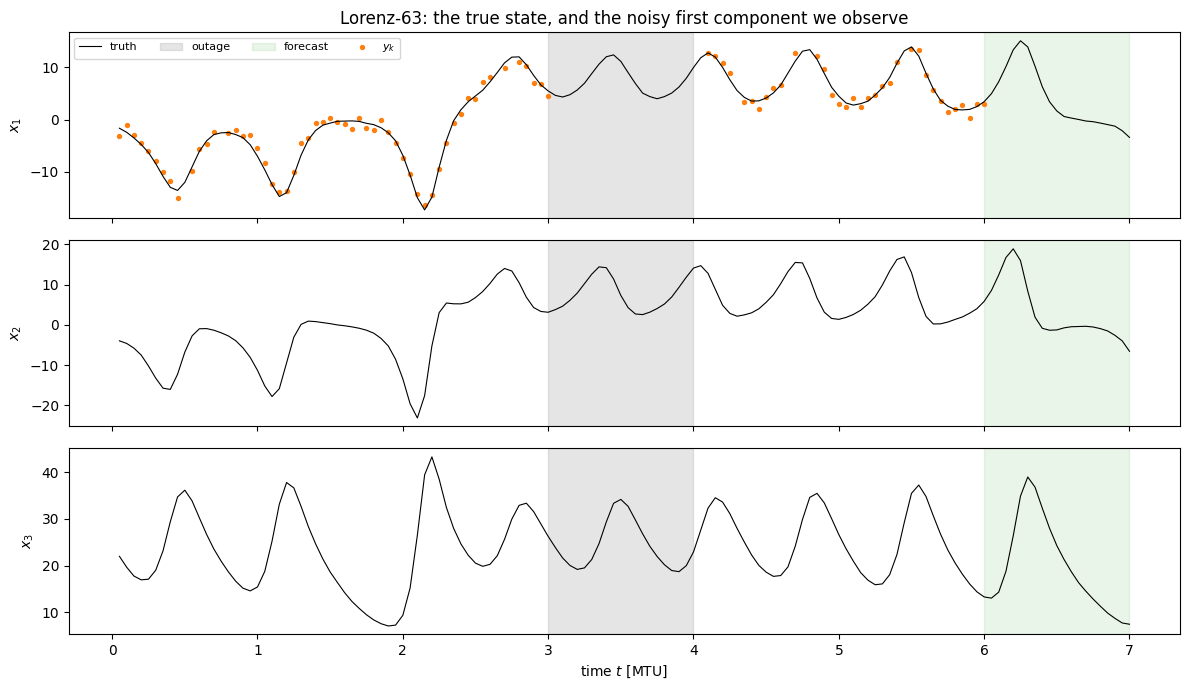

In [5]:
labels = ("$x_1$", "$x_2$", "$x_3$")
fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
for d, ax in enumerate(axes):
    ax.plot(times, x_true[:, d], "k-", lw=0.8, label="truth")
    ax.axvspan(3.0, 4.0, color="grey", alpha=0.2, label="outage")
    ax.axvspan(times[N_STEPS - 1], times[-1], color="C2", alpha=0.1, label="forecast")
    ax.set_ylabel(labels[d])
axes[0].scatter(times[mask_all], y_all[mask_all, 0], c="C1", s=8, label="$y_k$")
axes[0].legend(loc="upper left", fontsize=8, ncol=4)
axes[0].set_title("Lorenz-63: the true state, and the noisy first component we observe")
axes[-1].set_xlabel("time $t$ [MTU]")
plt.tight_layout()
plt.show()

Only $x_1$ is observed, and with a noise standard deviation of 1 on a signal that swings between about $-20$ and $20$. The other two components never reach the data, and the outage hides one excursion of the trajectory. The forecast window starts at the end of the record.

## 2. The model as a plain NumPyro function

The priors say what we would know before seeing the record: a Prandtl number of order 10, a Rayleigh number in the twenties and a noise variance below a few units, all positive. So we take $\sigma \sim \mathrm{LogNormal}(\log 8, 0.5^2)$, $\rho \sim \mathrm{LogNormal}(\log 25, 0.3^2)$ and $\boldsymbol{\Sigma}_\varepsilon \sim \mathrm{LogNormal}(\log 0.5, 1^2)$. We take a wide initial state, $\boldsymbol{\mu}_{x,0} = (0, 0, 25)$ and $\boldsymbol{\Sigma}_{x,0} = 64 \mathbf{I}_{D_x}$, about the spread of the attractor. Then `nonlinear_ssm_factor` takes $f$ built from the two sample sites, $h$, $\boldsymbol{\Sigma}_\eta$, $\boldsymbol{\Sigma}_\varepsilon$, the record, the initial moments and the mask, and registers the factor `"y"`. The first row of `y` is $\mathbf{y}_1$, scored after one step from $\mathbf{x}_0$.

In [6]:
# Shapes: D_θ = 3 parameters; T = 120 steps; D_x = 3; D_y = 1

# μ_x,0 and Σ_x,0
INIT_MEAN = jnp.array([0.0, 0.0, 25.0])  # → (D_x,)
INIT_COV = 64.0 * jnp.eye(3)  # → (D_x, D_x)
# today (gaussx): the factor's default rule, named so the smoother can reuse it
UNSCENTED = gaussx.UnscentedIntegrator(alpha=1.0)


def lorenz_model(y, mask, integrator=UNSCENTED):
    # today (numpyro): the three sample sites of θ
    # σ ~ LogNormal(log 8, 0.5²)
    sigma = numpyro.sample("sigma", dist.LogNormal(jnp.log(8.0), 0.5))
    # ρ ~ LogNormal(log 25, 0.3²)
    rho = numpyro.sample("rho", dist.LogNormal(jnp.log(25.0), 0.3))
    # Σ_ε ~ LogNormal(log 0.5, 1²)
    noise_var = numpyro.sample("noise_var", dist.LogNormal(jnp.log(0.5), 1.0))
    # today (pyrox_ssm), calling gaussx
    # log p(y_1:T ∣ θ) ≈ ∑ₖ oₖ log 𝒩(yₖ; μ_y,k, Σ_y,k)
    return nonlinear_ssm_factor(
        "y",
        lambda x: lorenz_step(x, sigma, rho),
        observe,
        PROCESS_NOISE,
        noise_var * jnp.eye(1),
        y,
        INIT_MEAN,
        INIT_COV,
        integrator=integrator,
        mask=mask,
    )


# today (numpyro)
seeded_model = handlers.seed(lorenz_model, rng_seed=0)
# today (numpyro)
trace = handlers.trace(seeded_model).get_trace(y, mask)
for name, site in trace.items():
    kind = "factor" if isinstance(site["fn"], dist.Unit) else type(site["fn"]).__name__
    print(f"site {name!r:14} {kind:<10} value shape={tuple(jnp.shape(site['value']))}")

site 'sigma'        LogNormal  value shape=()
site 'rho'          LogNormal  value shape=()
site 'noise_var'    LogNormal  value shape=()
site 'y'            factor     value shape=(0,)


So the trace holds three scalar sample sites and one factor, as in the earlier examples. The 120-step path of all three components is inside the filter, and NUTS never sees it.

## 3. NUTS, with forward-mode gradients

NUTS needs the gradient of the log density at every leapfrog step. The filter is a `jax.lax.scan` over 120 small steps, each with seven RK4 evaluations, so a reverse-mode gradient has to store and replay every one of them. With only three parameters, forward mode (three tangent passes alongside the filter) can be cheaper. We time the log likelihood, its reverse-mode gradient and its forward-mode Jacobian at the truth before choosing.

In [7]:
def log_lik(theta, integrator=UNSCENTED):
    """The factor's log p(y_1:T ∣ θ) at θ = (σ, ρ, Σ_ε), outside a model."""
    sigma, rho, noise_var = theta
    # today (pyrox_ssm), calling gaussx
    state = nonlinear_ssm_factor(
        "y",
        lambda x: lorenz_step(x, sigma, rho),
        observe,
        PROCESS_NOISE,
        noise_var * jnp.eye(1),
        y,
        INIT_MEAN,
        INIT_COV,
        integrator=integrator,
        mask=mask,
    )
    return state.log_likelihood


def time_ms(fn, theta, repeats=20):
    """Wall-clock time of one jitted call of ``fn`` at ``theta``, in ms."""
    # today (jax)
    jitted = jax.jit(fn)
    jax.block_until_ready(jitted(theta))
    t0 = time.perf_counter()
    for _ in range(repeats):
        jax.block_until_ready(jitted(theta))
    return 1e3 * (time.perf_counter() - t0) / repeats


theta_true = jnp.array([truth["sigma"], truth["rho"], truth["noise_var"]])  # → (3,)
# today (jax)
eval_ms = {
    "value": time_ms(log_lik, theta_true),
    "reverse-mode gradient": time_ms(jax.grad(log_lik), theta_true),
    "forward-mode Jacobian": time_ms(jax.jacfwd(log_lik), theta_true),
}
for label, ms in eval_ms.items():
    print(f"{label:<22} {ms:6.2f} ms")

value                    1.38 ms
reverse-mode gradient    8.86 ms
forward-mode Jacobian    4.34 ms


The forward-mode Jacobian (4.34 ms) costs half as much as the reverse-mode gradient (8.86 ms), or about three evaluations of the log likelihood (1.38 ms each). So we pass `forward_mode_differentiation=True` to NUTS. We run two chains of 200 draws after 100 warm-up steps, with a dense mass matrix, started at the prior medians and run one after the other (`chain_method="sequential"`). We cap the trajectories at $2^5$ leapfrog steps (`max_tree_depth=5`), which bounds the cost of the long early warm-up trajectories. The wall-clock time includes JIT compilation.

In [8]:
# Shapes: D_θ = 3 parameters; 2 chains × 200 = 400 posterior draws

# today (numpyro)
nuts_kernel = NUTS(
    lorenz_model,
    dense_mass=True,
    init_strategy=init_to_median,
    forward_mode_differentiation=True,
    max_tree_depth=5,
)
# today (numpyro)
nuts = MCMC(
    nuts_kernel,
    num_warmup=100,
    num_samples=200,
    num_chains=2,
    chain_method="sequential",
    progress_bar=False,
)
t0 = time.perf_counter()
# today (numpyro)
# 400 draws θ ~ p(θ ∣ y_1:T), under the unscented surrogate
nuts.run(jr.PRNGKey(1), y, mask, extra_fields=("num_steps",))
jax.block_until_ready(nuts.get_samples())
nuts_seconds = time.perf_counter() - t0
nuts.print_summary()
nuts_samples = nuts.get_samples()  # → {name: (400,)}
extra_fields = nuts.get_extra_fields()
n_div = int(extra_fields["diverging"].sum())  # → ()
n_grad = int(extra_fields["num_steps"].sum())  # → ()
print(
    f"NUTS wall-clock: {nuts_seconds:.1f} s for 2 chains x 300 iterations, "
    f"{n_div} divergences"
)
print(f"leapfrog steps after warm-up: {n_grad}, {n_grad / 400:.1f} per draw")


                 mean       std    median      5.0%     95.0%     n_eff     r_hat
  noise_var      0.91      0.15      0.90      0.66      1.15    304.18      1.00
        rho     28.12      0.46     28.10     27.44     28.91    363.56      1.00
      sigma     10.68      0.63     10.69      9.66     11.69    245.28      1.01

Number of divergences: 0
NUTS wall-clock: 51.2 s for 2 chains x 300 iterations, 0 divergences
leapfrog steps after warm-up: 1992, 5.0 per draw


## 4. The parameters against the truth

parameter      truth         mean ± sd          90% interval
sigma          10.00   10.683 ± 0.633   [ 9.700, 11.765]  in
rho            28.00   28.124 ± 0.460   [27.438, 28.905]  in
noise_var       1.00    0.909 ± 0.151   [ 0.682,  1.184]  in


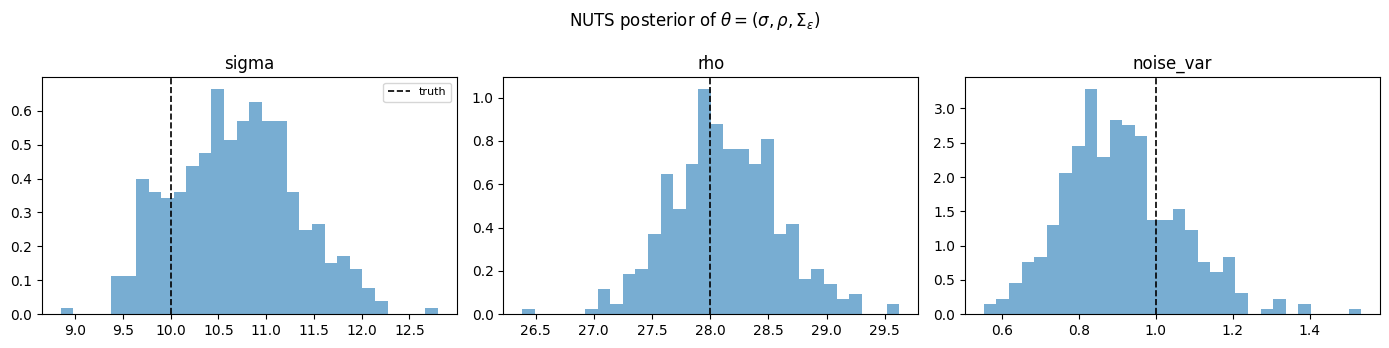

In [9]:
print(f"{'parameter':<12}{'truth':>8}  {'mean ± sd':>16}  {'90% interval':>20}")
for k in truth:
    v = np.asarray(nuts_samples[k])
    lo, hi = np.percentile(v, [5, 95])
    inside = "in" if lo <= truth[k] <= hi else "out"
    print(
        f"{k:<12}{truth[k]:>8.2f}  {v.mean():>7.3f} ± {v.std():<6.3f}  "
        f"[{lo:>6.3f}, {hi:>6.3f}] {inside:>3}"
    )

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, k in zip(axes, truth, strict=True):
    ax.hist(np.asarray(nuts_samples[k]), bins=30, density=True, alpha=0.6, color="C0")
    ax.axvline(truth[k], color="k", ls="--", lw=1.2, label="truth")
    ax.set_title(k)
axes[0].legend(fontsize=8)
fig.suptitle(r"NUTS posterior of $\theta = (\sigma, \rho, \Sigma_\varepsilon)$")
plt.tight_layout()
plt.show()

Both chains agree ($\hat{R} \le 1.01$), with no divergences and 5.0 leapfrog steps per draw, and all three 90 % intervals contain the true values. The Rayleigh number is pinned down best, at 28.124 ± 0.460 against the true 28. The Prandtl number comes out at 10.683 ± 0.633, about one posterior standard deviation above the true 10, and the noise variance at 0.909 ± 0.151 against 1. So one noisy component with gaps is enough to identify both parameters: $\sigma$ sets how fast $x_1$ follows $x_2$, and $\rho$ sets the size of the excursions of $x_2$ that $x_1$ follows. Keep in mind that this is the posterior under the unscented surrogate. Section 6 shows how much the surrogate depends on the integrator.

## 5. The smoothed state through the gaps, and a forecast

`nonlinear_ssm_factor` returns the gaussx `FilterState`, which holds the filtered and the predicted moments at every step. We pass it to `gaussx.nonlinear_rts_smoother` with the same $f$ and the same integrator, which gives $\boldsymbol{\mu}_{x,k \mid T}$ and $\boldsymbol{\Sigma}_{x,k \mid T}$. For the forecast we run the filter on all $T + T_\text{f}$ rows of the record, with the last $T_\text{f}$ masked. A masked step only predicts, and the smoother has no data after the record to correct with, so on the forecast steps the smoothed moments are the filter's predictions. We do this at $N_{\mathcal{E}} = 50$ NUTS draws $\boldsymbol{\theta}^{(e)}$, $e \in \mathcal{E}$, with `jax.vmap`. We combine them per component as in [Example 1](ssm_one_site.ipynb), with the mean over the draws of $\boldsymbol{\mu}_{x,k \mid T}^{(e)}$, and the mean of the variances plus the variance of the means. So the bands carry the uncertainty of $\boldsymbol{\theta}$ as well as that of the path. Since we simulated the record, we score them against the true state on the observed steps, the random dropouts, the outage and the forecast.

In [10]:
# Shapes: N_E = 50 draws; T + T_f = 140 steps; D_x = 3

N_DRAWS = 50


def smoothed_moments(theta, integrator=UNSCENTED):
    """μ_x,k∣T and the diagonal of Σ_x,k∣T over the record and the forecast."""
    dynamics = lambda x: lorenz_step(x, theta["sigma"], theta["rho"])
    # today (pyrox_ssm), outside a model, for the returned FilterState
    state = nonlinear_ssm_factor(
        "y",
        dynamics,
        observe,
        PROCESS_NOISE,
        theta["noise_var"] * jnp.eye(1),
        y_all,
        INIT_MEAN,
        INIT_COV,
        integrator=integrator,
        mask=mask_all,
    )
    # today (gaussx)
    # μ_x,k∣T, Σ_x,k∣T by the moment-matched RTS smoother
    smoothed = gaussx.nonlinear_rts_smoother(state, dynamics, integrator=integrator)
    means, covs = smoothed  # → (T + T_f, D_x), (T + T_f, D_x, D_x)
    # the per-component variances, diag Σ_x,k∣T
    variances = einx.id("time d d -> time d", covs)  # → (T + T_f, D_x)
    return means, variances


# N_E draws θ⁽ᵉ⁾, evenly spaced through the chains
draw_idx = jnp.linspace(0, 399, N_DRAWS).astype(int)  # → (N_E,)
theta_draws = {k: v[draw_idx] for k, v in nuts_samples.items()}
t0 = time.perf_counter()
# today (jax)
smooth_draws = jax.jit(jax.vmap(smoothed_moments))
means, variances = smooth_draws(theta_draws)  # → 2 × (N_E, T + T_f, D_x)
jax.block_until_ready(means)
smooth_seconds = time.perf_counter() - t0
# 𝔼[x_k ∣ y_1:T] ≈ (1/N_E) ∑ₑ μ_x,k∣T⁽ᵉ⁾
state_mean = einx.mean("draw time d -> time d", means)  # → (T + T_f, D_x)
# (1/N_E) ∑ₑ diag Σ_x,k∣T⁽ᵉ⁾
within = einx.mean("draw time d -> time d", variances)  # → (T + T_f, D_x)
# the spread of μ_x,k∣T⁽ᵉ⁾ over the draws
between = einx.var("draw time d -> time d", means)  # → (T + T_f, D_x)
state_sd = jnp.sqrt(within + between)  # → (T + T_f, D_x)
print(f"{N_DRAWS} filter and smoother runs: {smooth_seconds:.1f} s (with JIT)")

segments = {
    "observed": mask_all,
    "random dropouts": dropout & ~outage & ~forecast,
    "outage": outage,
    "forecast": forecast,
}


def score(mean, sd):
    """Coverage of ±2σ and RMSE per component on each segment."""
    # z = (x_k − 𝔼[x_k ∣ y_1:T]) / sd
    z = (x_true - mean) / sd  # → (T + T_f, D_x)
    rows = {}
    for label, sel in segments.items():
        cover = einx.mean("[time] d", jnp.abs(z[sel]) < 2.0)  # → (D_x,)
        sq_err = (x_true - mean)[sel] ** 2  # → (n, D_x)
        rmse = jnp.sqrt(einx.mean("[time] d", sq_err))  # → (D_x,)
        rows[label] = (int(sel.sum()), cover, rmse)
    return rows


print(
    f"{'segment':<16}{'n':>4}  {'coverage of ±2σ (x1, x2, x3)':>30}"
    f"  {'RMSE (x1, x2, x3)':>20}"
)
for label, (n, cover, rmse) in score(state_mean, state_sd).items():
    cov_txt = ", ".join(f"{100 * float(c):5.1f}" for c in cover)
    rmse_txt = ", ".join(f"{float(r):5.2f}" for r in rmse)
    print(f"{label:<16}{n:>4}  {cov_txt:>30}  {rmse_txt:>20}")

50 filter and smoother runs: 2.9 s (with JIT)
segment            n    coverage of ±2σ (x1, x2, x3)     RMSE (x1, x2, x3)


observed          90              95.6,  92.2, 100.0    0.25,  0.47,  0.56
random dropouts   10             100.0, 100.0, 100.0    0.21,  0.50,  0.35
outage            20             100.0, 100.0, 100.0    0.24,  0.24,  0.30
forecast          20             100.0, 100.0, 100.0    2.09,  2.65,  4.28


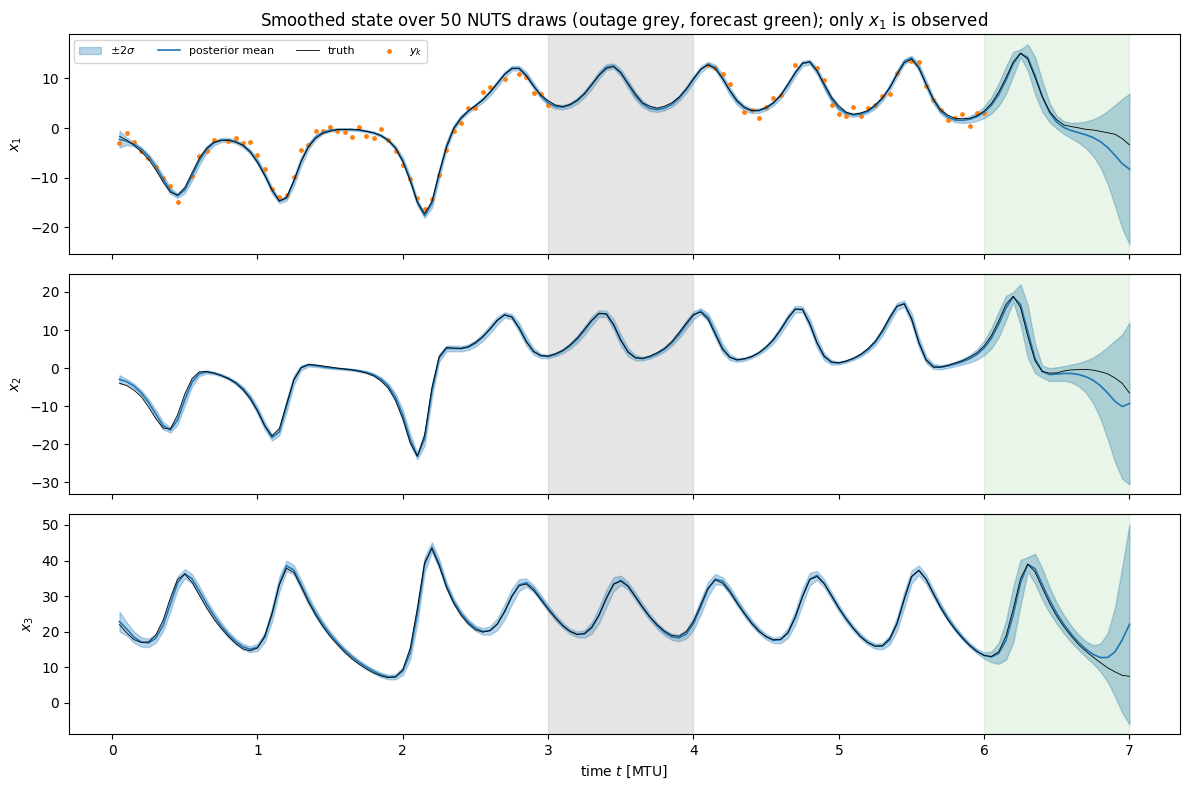

In [11]:
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for d, ax in enumerate(axes):
    lo = state_mean[:, d] - 2 * state_sd[:, d]
    hi = state_mean[:, d] + 2 * state_sd[:, d]
    ax.fill_between(times, lo, hi, color="C0", alpha=0.3, label=r"$\pm 2\sigma$")
    ax.plot(times, state_mean[:, d], "C0", lw=1.2, label="posterior mean")
    ax.plot(times, x_true[:, d], "k-", lw=0.6, label="truth")
    ax.axvspan(3.0, 4.0, color="grey", alpha=0.2)
    ax.axvspan(times[N_STEPS - 1], times[-1], color="C2", alpha=0.1)
    ax.set_ylabel(labels[d])
axes[0].scatter(times[mask_all], y_all[mask_all, 0], c="C1", s=6, label="$y_k$")
axes[0].legend(loc="upper left", fontsize=8, ncol=4)
axes[0].set_title(
    "Smoothed state over 50 NUTS draws (outage grey, forecast green); only $x_1$ is observed"
)
axes[-1].set_xlabel("time $t$ [MTU]")
plt.tight_layout()
plt.show()

The posterior mean follows the truth in all three components, also in $x_2$ and $x_3$, which never reach the data: the dynamics couple them to $x_1$, so the filter infers them from how $x_1$ moves. On the observed steps the $\pm 2\sigma$ band covers 95.6 %, 92.2 % and 100 % of the true values of $x_1$, $x_2$ and $x_3$, with RMSEs of 0.25, 0.47 and 0.56. The band hardly widens through the outage, where every true value is inside it and the RMSEs (0.24, 0.24 and 0.30) are no worse than on the observed steps. The smoother has the record on both sides of the gap, and with model noise as small as $\boldsymbol{\Sigma}_\eta$ only a narrow set of paths joins the two ends. The forecast has data on one side only, and there the band opens within 1 MTU to a good part of the range of the attractor. The RMSEs grow to 2.09, 2.65 and 4.28, and the band still covers every true value. This is the predictability limit of a chaotic system, seen from the filter: the record pins the state down tightly, and the forecast loses that within about one MTU.

## 6. The unscented against the extended Kalman filter

We now swap the integrator for `gaussx.TaylorIntegrator()`, the EKF, and keep everything else. We compare the two at the NUTS posterior mean $\bar{\boldsymbol{\theta}}$ in three ways. We look at the log likelihood and its cost per evaluation, at the profile of the log likelihood in $\rho$ with $\sigma$ and $\boldsymbol{\Sigma}_\varepsilon$ held at their posterior means (81 values, one filter pass each), and at the smoothed state on the outage and the forecast. A second NUTS run under the EKF would answer the same question more fully, but it costs as much as section 3 again.

In [12]:
# Shapes: D_θ = 3; N_ρ = 81 values of ρ; T + T_f = 140 steps; D_x = 3

# today (gaussx)
TAYLOR = gaussx.TaylorIntegrator()
integrators = {"unscented": UNSCENTED, "extended (Taylor)": TAYLOR}
# θ̄, the NUTS posterior mean
theta_bar = {k: jnp.mean(v) for k, v in nuts_samples.items()}
theta_bar_vec = jnp.array([theta_bar[k] for k in truth])  # → (3,)
rho_grid = jnp.linspace(24.0, 32.0, 81)  # → (N_ρ,)
compare = {}
for label, rule in integrators.items():
    ll_fn = lambda th, rule=rule: log_lik(th, integrator=rule)

    def profile_one(rho, ll_fn=ll_fn):
        return ll_fn(theta_bar_vec.at[1].set(rho))

    # today (jax): log p(y_1:T ∣ σ̄, ρ, Σ̄_ε), one ρ at a time
    profile = jax.jit(lambda grid, f=profile_one: jax.lax.map(f, grid))(rho_grid)
    mean, var = smoothed_moments(theta_bar, integrator=rule)  # → 2 × (T + T_f, D_x)
    compare[label] = {
        "log_lik": float(ll_fn(theta_bar_vec)),
        "value_ms": time_ms(ll_fn, theta_bar_vec),
        "fwd_ms": time_ms(jax.jacfwd(ll_fn), theta_bar_vec),
        "profile": profile,
        "rho_max": float(rho_grid[jnp.argmax(profile)]),
        "mean": mean,
        "sd": jnp.sqrt(var),
    }

print(
    f"{'integrator':<20}{'log p(y | theta_bar)':>21}{'argmax rho':>12}"
    f"{'value, ms':>11}{'fwd grad, ms':>14}"
)
for label, c in compare.items():
    print(
        f"{label:<20}{c['log_lik']:>21.2f}{c['rho_max']:>12.2f}"
        f"{c['value_ms']:>11.2f}{c['fwd_ms']:>14.2f}"
    )
print()
print(
    f"{'integrator':<20}{'segment':<10}{'coverage (x1, x2, x3)':>24}"
    f"{'RMSE (x1, x2, x3)':>21}"
)
for label, c in compare.items():
    rows = score(c["mean"], c["sd"])
    for seg in ("outage", "forecast"):
        _, cover, rmse = rows[seg]
        cov_txt = ", ".join(f"{100 * float(v):5.1f}" for v in cover)
        rmse_txt = ", ".join(f"{float(v):5.2f}" for v in rmse)
        print(f"{label:<20}{seg:<10}{cov_txt:>24}{rmse_txt:>21}")
gap = jnp.abs(compare["unscented"]["mean"] - compare["extended (Taylor)"]["mean"])
print()
for label, sel in (("observed", mask_all), ("outage", outage), ("forecast", forecast)):
    print(
        f"max |difference of the smoothed means| on {label:<9}: {float(gap[sel].max()):.2f}"
    )

integrator           log p(y | theta_bar)  argmax rho  value, ms  fwd grad, ms
unscented                         -139.24       28.20       1.42          4.49
extended (Taylor)                 -140.22       27.70       1.23          7.55

integrator          segment      coverage (x1, x2, x3)    RMSE (x1, x2, x3)
unscented           outage          95.0, 100.0, 100.0   0.24,  0.24,  0.30
unscented           forecast       100.0, 100.0, 100.0   2.24,  2.85,  4.20
extended (Taylor)   outage         100.0, 100.0, 100.0   0.18,  0.21,  0.24
extended (Taylor)   forecast        55.0,  65.0,  95.0   3.70,  5.38,  5.55



max |difference of the smoothed means| on observed : 1.03
max |difference of the smoothed means| on outage   : 0.40
max |difference of the smoothed means| on forecast : 9.58


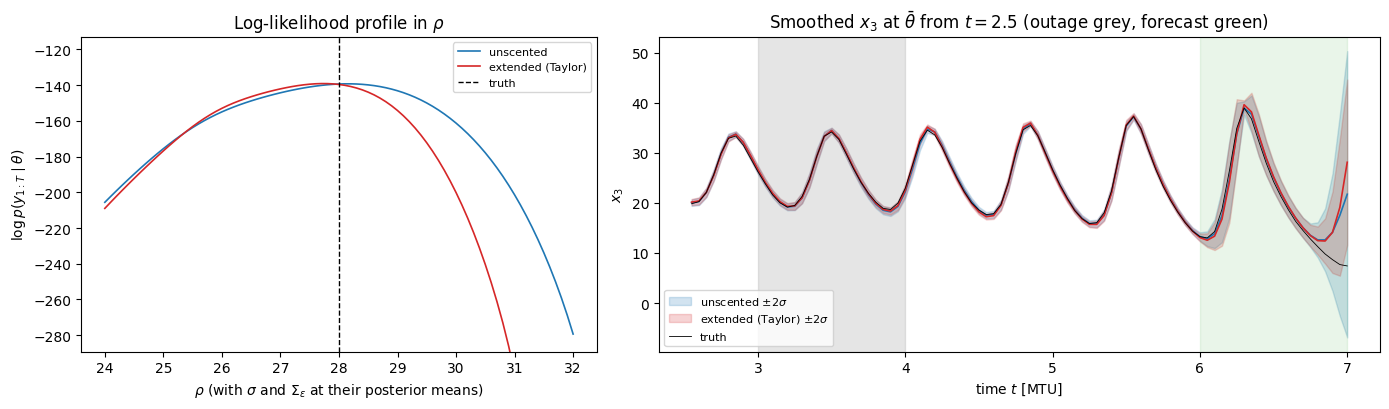

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), width_ratios=(1, 1.4))
ax = axes[0]
for (label, c), color in zip(compare.items(), ("C0", "C3"), strict=True):
    ax.plot(rho_grid, c["profile"], color=color, lw=1.2, label=label)
ax.axvline(truth["rho"], color="k", ls="--", lw=1, label="truth")
ax.set_ylim(compare["unscented"]["profile"].max() - 150.0, None)
ax.set_xlabel(
    r"$\rho$ (with $\sigma$ and $\Sigma_\varepsilon$ at their posterior means)"
)
ax.set_ylabel(r"$\log p(y_{1:T} \mid \theta)$")
ax.set_title("Log-likelihood profile in $\\rho$")
ax.legend(fontsize=8)
ax = axes[1]
win = times > 2.5
d = 2
for (label, c), color in zip(compare.items(), ("C0", "C3"), strict=True):
    lo = (c["mean"][:, d] - 2 * c["sd"][:, d])[win]
    hi = (c["mean"][:, d] + 2 * c["sd"][:, d])[win]
    ax.fill_between(
        times[win], lo, hi, color=color, alpha=0.2, label=rf"{label} $\pm 2\sigma$"
    )
    ax.plot(times[win], c["mean"][win, d], color=color, lw=1.2)
ax.plot(times[win], x_true[win, d], "k-", lw=0.6, label="truth")
ax.axvspan(3.0, 4.0, color="grey", alpha=0.2)
ax.axvspan(times[N_STEPS - 1], times[-1], color="C2", alpha=0.1)
ax.set_xlabel("time $t$ [MTU]")
ax.set_ylabel("$x_3$")
ax.set_title(
    r"Smoothed $x_3$ at $\bar{\theta}$ from $t = 2.5$ (outage grey, forecast green)"
)
ax.legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

At $\bar{\boldsymbol{\theta}}$ the two log likelihoods are close, −139.24 for the unscented filter and −140.22 for the EKF. The profiles in $\rho$ tell them apart. Below the true $\rho = 28$ they nearly coincide, but above it the EKF profile falls off much faster. Its maximum on the grid is at $\rho = 27.70$ against 28.20 for the unscented one. That shift is about one posterior standard deviation of $\rho$ (0.460), so the choice of rule alone would move the inferred Rayleigh number by that much. Neither surrogate is the exact likelihood, and this comparison does not say which one is closer to it.

The smoothed states agree on the record, where the means differ by at most 1.03. They also agree in the outage, where they differ by at most 0.40 and the EKF is even slightly closer to the truth (RMSEs of 0.18, 0.21 and 0.24 against 0.24, 0.24 and 0.30). In the forecast they part ways. There the means differ by up to 9.58, and the EKF's RMSEs grow to 3.70, 5.38 and 5.55 against 2.24, 2.85 and 4.20. Its band covers only 55 % and 65 % of the true $x_1$ and $x_2$ (95 % of $x_3$), while the unscented band covers all of them. On the record the belief is narrow, so $f$ is close to linear across it and both rules give the same moments. In the forecast the belief is wide, and the linearisation at the mean misses the spread that the sigma points pick up, so the EKF is overconfident exactly where the uncertainty matters.

One evaluation costs 1.42 ms with the unscented rule and 1.23 ms with the EKF, so the seven sigma points cost little more than one Jacobian. The forward-mode gradient goes the other way, 4.49 ms against 7.55 ms, because the EKF's gradient differentiates through $\mathbf{J}_f$, a second derivative of the RK4 step. So on this model the unscented default is both the cheaper filter for NUTS and the better-calibrated one.

## Summary

- A nonlinear state-space model is a plain NumPyro function: priors on $\boldsymbol{\theta}$, the dynamics $f$ built from the sample sites, and `nonlinear_ssm_factor("y", f, h, Σ_η, Σ_ε, y, μ_x0, Σ_x0, mask=mask)`. The default integrator is the unscented rule with `alpha=1.0`, which needs no derivatives of $f$.
- NUTS on $(\sigma, \rho, \boldsymbol{\Sigma}_\varepsilon)$ from 90 noisy observations of $x_1$ took 51.2 s with forward-mode gradients, with no divergences and 5.0 leapfrog steps per draw. All three 90 % intervals contain the truth, and $\rho$ comes out at 28.124 ± 0.460.
- The `FilterState` that the factor returns, passed to `gaussx.nonlinear_rts_smoother`, gives the smoothed state, including the two components that are never observed. Averaged over 50 NUTS draws, the band bridges the 1 MTU outage tightly and opens in the forecast, and it covers every true value in both.
- The integrator is a modelling choice. The unscented filter and the EKF agree on the record, but their likelihood profiles peak at $\rho = 28.20$ and 27.70, and in the forecast the EKF band covers only 55 % of the true $x_1$.
- One log likelihood costs 1.38 ms and one forward-mode gradient 4.34 ms at $T = 120$ (the reverse-mode gradient 8.86 ms), so NUTS is the expensive step here.

For linear dynamics, where the Kalman filter is exact, see [Example 1](ssm_one_site.ipynb). For a state too large to carry a $D_x \times D_x$ covariance, see the ensemble filter of [Example 5](ssm_ensemble.ipynb).